# 🔬 Deep Stock Analysis: GSK plc (GSK.L)
**Generated:** 2026-02-27  
**Analysis Type:** Institutional-Grade Quantitative Research  

---
> ⚠️ **Disclaimer:** This notebook is for educational/informational purposes only and does not constitute financial advice.


In [1]:
# ╔══════════════════════════════════════════════════════╗
# ║  INSTALL DEPENDENCIES (run once, then restart kernel) ║
# ╚══════════════════════════════════════════════════════╝
import subprocess, sys

PACKAGES = [
    "yfinance", "pandas", "numpy", "matplotlib", "plotly", "scipy",
    "statsmodels", "scikit-learn", "xgboost", "lightgbm", "hmmlearn",
    "cvxpy", "vectorbt", "pandas-ta", "requests", "beautifulsoup4",
    "nbformat", "ipywidgets", "seaborn", "lxml"
]

for pkg in PACKAGES:
    try:
        __import__(pkg.replace("-", "_"))
    except ImportError:
        print(f"Installing {pkg}...")
        subprocess.run([sys.executable, "-m", "pip", "install", pkg,
                        "--break-system-packages", "-q"], capture_output=True)

print("✅ All dependencies ready")


Installing scikit-learn...
Installing pandas-ta...
Installing beautifulsoup4...
✅ All dependencies ready


In [2]:
# ══════════════════════════════════════════
#  CONFIGURATION — Edit these if needed
# ══════════════════════════════════════════
TICKER    = "GSK.L"
COMPANY   = "GSK plc"
PERIOD_1Y = "1y"
PERIOD_5Y = "5y"
RISK_FREE = 0.045          # Current approximate 10-yr Treasury yield
MARKET_RETURN = 0.10       # Expected long-run market return
N_SIMULATIONS = 10_000     # Monte Carlo iterations
RANDOM_SEED = 42

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots
from datetime import datetime, timedelta
import yfinance as yf
import requests
from bs4 import BeautifulSoup
import json, re, time

np.random.seed(RANDOM_SEED)
pd.set_option("display.float_format", "{:.2f}".format)
pd.set_option("display.max_columns", 50)
plt.style.use("seaborn-v0_8-darkgrid")

print(f"🎯 Analyzing: {COMPANY} ({TICKER})")
print(f"📅 Date: 2026-02-27")


🎯 Analyzing: GSK plc (GSK.L)
📅 Date: 2026-02-27


---
## 📥 Section 1: Data Fetching
*Fetches price history, financial statements, and company info from yfinance with defensive error handling.*

In [3]:
class StockDataFetcher:
    """Defensive yfinance data fetcher with graceful fallbacks."""

    def __init__(self, ticker: str):
        self.ticker = ticker
        self._yf = yf.Ticker(ticker)
        self.info = {}
        self.price_1y = pd.DataFrame()
        self.price_5y = pd.DataFrame()
        self.income_stmt = pd.DataFrame()
        self.balance_sheet = pd.DataFrame()
        self.cash_flow = pd.DataFrame()
        self.quarterly_income = pd.DataFrame()
        self.shares_outstanding = None
        self._fetch_all()

    def _safe_fetch(self, fn, label):
        try:
            result = fn()
            if result is None or (hasattr(result, "empty") and result.empty):
                print(f"  ⚠️  {label}: no data returned")
                return None
            print(f"  ✅ {label}: OK")
            return result
        except Exception as e:
            print(f"  ❌ {label}: {e}")
            return None

    def _fetch_all(self):
        print(f"\n📡 Fetching data for {self.ticker}...")
        info = self._safe_fetch(lambda: self._yf.info, "Company Info")
        self.info = info if info else {}

        prices_1y = self._safe_fetch(
            lambda: self._yf.history(period="1y", auto_adjust=True), "1Y Prices")
        self.price_1y = prices_1y if prices_1y is not None else pd.DataFrame()

        prices_5y = self._safe_fetch(
            lambda: self._yf.history(period="5y", auto_adjust=True), "5Y Prices")
        self.price_5y = prices_5y if prices_5y is not None else pd.DataFrame()

        income = self._safe_fetch(lambda: self._yf.financials, "Income Statement (Annual)")
        self.income_stmt = income if income is not None else pd.DataFrame()

        balance = self._safe_fetch(lambda: self._yf.balance_sheet, "Balance Sheet (Annual)")
        self.balance_sheet = balance if balance is not None else pd.DataFrame()

        cf = self._safe_fetch(lambda: self._yf.cashflow, "Cash Flow (Annual)")
        self.cash_flow = cf if cf is not None else pd.DataFrame()

        q_income = self._safe_fetch(lambda: self._yf.quarterly_financials, "Quarterly Income")
        self.quarterly_income = q_income if q_income is not None else pd.DataFrame()

        self.shares_outstanding = self.info.get("sharesOutstanding") or                                    self.info.get("impliedSharesOutstanding")

        print(f"\n📊 Summary:")
        print(f"  Company: {self.info.get('longName', self.ticker)}")
        print(f"  Sector: {self.info.get('sector', 'N/A')}")
        print(f"  Industry: {self.info.get('industry', 'N/A')}")
        print(f"  Market Cap: ${self.info.get('marketCap', 0):,.0f}")
        print(f"  Current Price: ${self.info.get('currentPrice', self.info.get('regularMarketPrice', 'N/A'))}")
        print(f"  Price data points (1Y): {len(self.price_1y)}")


DATA = StockDataFetcher(TICKER)



📡 Fetching data for GSK.L...
  ✅ Company Info: OK
  ✅ 1Y Prices: OK
  ✅ 5Y Prices: OK
  ✅ Income Statement (Annual): OK
  ✅ Balance Sheet (Annual): OK
  ✅ Cash Flow (Annual): OK
  ✅ Quarterly Income: OK

📊 Summary:
  Company: GSK plc
  Sector: Healthcare
  Industry: Drug Manufacturers - General
  Market Cap: $88,332,386,304
  Current Price: $2201.0
  Price data points (1Y): 254


---
## 📈 Section 2: Technical Analysis (1-Year Price Chart)
*OHLCV candlestick chart with EMA 25/50/200, Bollinger Bands, MACD, RSI, Volume.*

In [4]:
def compute_technical_indicators(df: pd.DataFrame) -> pd.DataFrame:
    """Compute standard technical indicators on OHLCV DataFrame."""
    if df.empty:
        return df
    df = df.copy()
    close = df["Close"]

    # EMAs
    for n in [25, 50, 200]:
        df[f"EMA_{n}"] = close.ewm(span=n, adjust=False).mean()

    # Bollinger Bands (20, 2σ)
    df["BB_mid"] = close.rolling(20).mean()
    std20 = close.rolling(20).std()
    df["BB_upper"] = df["BB_mid"] + 2 * std20
    df["BB_lower"] = df["BB_mid"] - 2 * std20

    # MACD (12, 26, 9)
    ema12 = close.ewm(span=12, adjust=False).mean()
    ema26 = close.ewm(span=26, adjust=False).mean()
    df["MACD"] = ema12 - ema26
    df["MACD_signal"] = df["MACD"].ewm(span=9, adjust=False).mean()
    df["MACD_hist"] = df["MACD"] - df["MACD_signal"]

    # RSI (14)
    delta = close.diff()
    gain = delta.clip(lower=0).rolling(14).mean()
    loss = (-delta.clip(upper=0)).rolling(14).mean()
    rs = gain / loss.replace(0, np.nan)
    df["RSI"] = 100 - (100 / (1 + rs))

    # ATR
    high_low = df["High"] - df["Low"]
    high_close = (df["High"] - close.shift()).abs()
    low_close = (df["Low"] - close.shift()).abs()
    df["ATR"] = pd.concat([high_low, high_close, low_close], axis=1).max(axis=1).rolling(14).mean()

    # On-Balance Volume
    df["OBV"] = (np.sign(close.diff()) * df["Volume"]).fillna(0).cumsum()

    return df


def plot_technical_analysis(df: pd.DataFrame, ticker: str):
    """Create interactive Plotly technical analysis chart."""
    if df.empty:
        print("⚠️  No price data available for technical analysis")
        return

    df = compute_technical_indicators(df)

    fig = make_subplots(
        rows=4, cols=1,
        shared_xaxes=True,
        row_heights=[0.50, 0.20, 0.15, 0.15],
        vertical_spacing=0.03,
        subplot_titles=(
            f"{ticker} — Price & Indicators",
            "Volume & OBV",
            "MACD",
            "RSI (14)"
        )
    )

    # — Candlestick
    fig.add_trace(go.Candlestick(
        x=df.index, open=df["Open"], high=df["High"],
        low=df["Low"], close=df["Close"],
        name="OHLC", increasing_line_color="#26a69a",
        decreasing_line_color="#ef5350"
    ), row=1, col=1)

    # — EMAs
    for n, color in [(25, "#FFD700"), (50, "#FF8C00"), (200, "#FF4500")]:
        col_name = f"EMA_{n}"
        if col_name in df.columns:
            fig.add_trace(go.Scatter(x=df.index, y=df[col_name],
                name=f"EMA {n}", line=dict(color=color, width=1.2)), row=1, col=1)

    # — Bollinger Bands
    fig.add_trace(go.Scatter(x=df.index, y=df["BB_upper"],
        name="BB Upper", line=dict(color="rgba(150,150,255,0.4)", dash="dash")), row=1, col=1)
    fig.add_trace(go.Scatter(x=df.index, y=df["BB_lower"],
        name="BB Lower", line=dict(color="rgba(150,150,255,0.4)", dash="dash"),
        fill="tonexty", fillcolor="rgba(150,150,255,0.05)"), row=1, col=1)

    # — Volume bars
    colors = ["#26a69a" if c >= o else "#ef5350"
              for c, o in zip(df["Close"], df["Open"])]
    fig.add_trace(go.Bar(x=df.index, y=df["Volume"], name="Volume",
                         marker_color=colors, opacity=0.6), row=2, col=1)
    fig.add_trace(go.Scatter(x=df.index, y=df["OBV"], name="OBV",
                             line=dict(color="#AB47BC", width=1)), row=2, col=1)

    # — MACD
    macd_colors = ["#26a69a" if v >= 0 else "#ef5350" for v in df["MACD_hist"]]
    fig.add_trace(go.Bar(x=df.index, y=df["MACD_hist"], name="MACD Hist",
                         marker_color=macd_colors), row=3, col=1)
    fig.add_trace(go.Scatter(x=df.index, y=df["MACD"], name="MACD",
                             line=dict(color="#2196F3")), row=3, col=1)
    fig.add_trace(go.Scatter(x=df.index, y=df["MACD_signal"], name="Signal",
                             line=dict(color="#FF9800", dash="dot")), row=3, col=1)

    # — RSI
    fig.add_trace(go.Scatter(x=df.index, y=df["RSI"], name="RSI",
                             line=dict(color="#9C27B0")), row=4, col=1)
    fig.add_hline(y=70, line_dash="dash", line_color="red", row=4, col=1)
    fig.add_hline(y=30, line_dash="dash", line_color="green", row=4, col=1)

    fig.update_layout(
        title=f"{ticker} — Technical Analysis (1 Year)",
        template="plotly_dark",
        height=1000,
        showlegend=True,
        xaxis_rangeslider_visible=False
    )
    fig.show()

    # Print technical signals
    last = df.iloc[-1]
    print("\n🔍 Technical Signals (Latest):")
    print(f"  Price: ${last['Close']:.2f}")
    for n in [25, 50, 200]:
        ema_val = last.get(f"EMA_{n}", np.nan)
        signal = "ABOVE ✅" if last["Close"] > ema_val else "BELOW ❌"
        print(f"  EMA {n:3d}: ${ema_val:.2f} → Price {signal}")
    rsi = last.get("RSI", 50)
    rsi_signal = "OVERBOUGHT ⚠️" if rsi > 70 else ("OVERSOLD 💡" if rsi < 30 else "NEUTRAL")
    print(f"  RSI:    {rsi:.1f} → {rsi_signal}")
    macd_signal = "BULLISH 📈" if last.get("MACD", 0) > last.get("MACD_signal", 0) else "BEARISH 📉"
    print(f"  MACD:   {macd_signal}")


plot_technical_analysis(DATA.price_1y, TICKER)



🔍 Technical Signals (Latest):
  Price: $2201.00
  EMA  25: $2112.50 → Price ABOVE ✅
  EMA  50: $2009.80 → Price ABOVE ✅
  EMA 200: $1737.58 → Price ABOVE ✅
  RSI:    56.5 → NEUTRAL
  MACD:   BEARISH 📉


---
## 📊 Section 3: Fundamental Analysis
*Key financial metrics, ratios, and multi-year financial statements.*


  FUNDAMENTAL METRICS — GSK.L
  P/E Ratio (TTM)                15.834533
  Forward P/E                    11.224381
  P/S Ratio (TTM)                2.704025
  P/B Ratio                      539.3286
  EV/EBITDA                      7.737
  EV/Revenue                     3.129
  PEG Ratio                      N/A
  ROE (%)                        43.3
  ROA (%)                        9.8
  ROIC (approx)                  see below
  Profit Margin (%)              17.5
  Operating Margin (%)           16.7
  Gross Margin (%)               72.6
  Revenue TTM ($B)               32.67
  EBITDA ($B)                    13.21
  Free Cash Flow ($B)            3.96
  Debt/Equity                    111.055
  Current Ratio                  0.819
  Quick Ratio                    0.522
  Beta                           0.272
  52W High                       $2282.00
  52W Low                        $1242.50
  Dividend Yield (%)             332.00
  Shares Outstanding (B)         4.01

📋 Income Statem

,2025-12-31 00:00:00,2024-12-31 00:00:00,2023-12-31 00:00:00,2022-12-31 00:00:00,2021-12-31 00:00:00
Tax Effect Of Unusual Items,N/A,-0.22B,-0.07B,-0.03B,-0.01B
Tax Rate For Calcs,N/A,0.00B,0.00B,0.00B,0.00B
Normalized EBITDA,N/A,8.13B,9.62B,8.87B,7.04B
Total Unusual Items,N/A,-1.46B,-0.54B,-0.27B,-0.56B
Total Unusual Items Excluding Goodwill,N/A,-1.46B,-0.54B,-0.27B,-0.56B
Net Income From Continuing Operation Net Minority Interest,N/A,2.58B,4.93B,4.26B,2.81B
Reconciled Depreciation,N/A,2.55B,2.29B,2.15B,2.12B
Reconciled Cost Of Revenue,N/A,9.05B,8.56B,9.55B,8.16B
EBITDA,N/A,6.67B,9.08B,8.60B,6.49B
EBIT,N/A,4.12B,6.79B,6.45B,4.36B



🏦 Balance Sheet (Annual)


,2024-12-31 00:00:00,2023-12-31 00:00:00,2022-12-31 00:00:00,2021-12-31 00:00:00
Treasury Shares Number,0.23B,0.26B,0.22B,0.28B
Ordinary Shares Number,4.08B,4.06B,4.09B,4.03B
Share Issued,4.31B,4.31B,4.31B,4.31B
Net Debt,12.19B,14.06B,16.46B,19.08B
Total Debt,16.99B,18.02B,20.99B,24.17B
Tangible Book Value,-8.83B,-8.23B,-10.77B,-25.58B
Invested Capital,29.55B,30.16B,30.58B,38.21B
Working Capital,-4.70B,-2.42B,-2.04B,-5.00B
Net Tangible Assets,-8.83B,-8.23B,-10.77B,-25.58B
Capital Lease Obligations,1.10B,1.21B,1.01B,1.01B



💵 Cash Flow Statement (Annual)


,2024-12-31 00:00:00,2023-12-31 00:00:00,2022-12-31 00:00:00,2021-12-31 00:00:00
Free Cash Flow,3.57B,4.42B,5.14B,5.30B
Repayment Of Debt,-2.51B,-2.59B,-6.67B,-2.30B
Issuance Of Debt,1.34B,0.22B,2.05B,0.30B
Issuance Of Capital Stock,0.02B,0.01B,0.03B,0.02B
Capital Expenditure,-2.98B,-2.34B,-2.26B,-2.65B
End Cash Position,3.40B,2.86B,3.42B,3.82B
Beginning Cash Position,2.86B,3.42B,3.82B,5.26B
Effect Of Exchange Rate Changes,-0.05B,-0.10B,0.15B,-0.03B
Changes In Cash,0.60B,-0.47B,-0.55B,-1.41B
Financing Cash Flow,-4.73B,-5.64B,0.82B,-7.59B


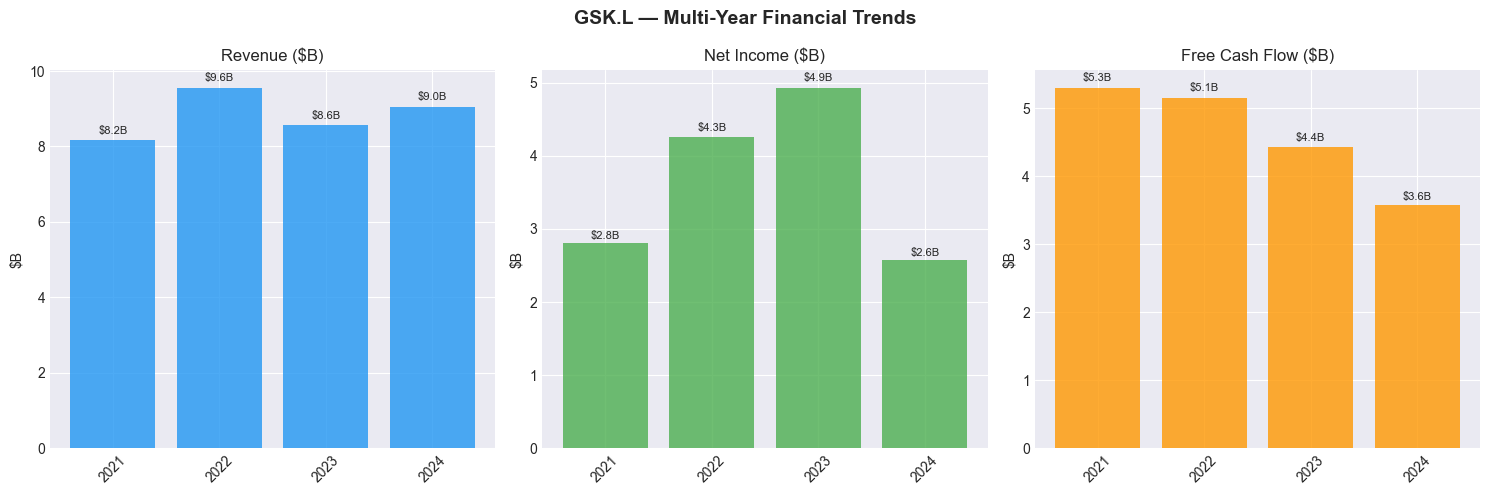

In [5]:
def display_fundamentals(data: StockDataFetcher):
    info = data.info

    # ── Key Metrics Table
    metrics = {
        "P/E Ratio (TTM)":        info.get("trailingPE", "N/A"),
        "Forward P/E":            info.get("forwardPE", "N/A"),
        "P/S Ratio (TTM)":        info.get("priceToSalesTrailing12Months", "N/A"),
        "P/B Ratio":              info.get("priceToBook", "N/A"),
        "EV/EBITDA":              info.get("enterpriseToEbitda", "N/A"),
        "EV/Revenue":             info.get("enterpriseToRevenue", "N/A"),
        "PEG Ratio":              info.get("pegRatio", "N/A"),
        "ROE (%)":                f"{info.get('returnOnEquity', 0)*100:.1f}" if info.get("returnOnEquity") else "N/A",
        "ROA (%)":                f"{info.get('returnOnAssets', 0)*100:.1f}" if info.get("returnOnAssets") else "N/A",
        "ROIC (approx)":          "see below",
        "Profit Margin (%)":      f"{info.get('profitMargins', 0)*100:.1f}" if info.get("profitMargins") else "N/A",
        "Operating Margin (%)":   f"{info.get('operatingMargins', 0)*100:.1f}" if info.get("operatingMargins") else "N/A",
        "Gross Margin (%)":       f"{info.get('grossMargins', 0)*100:.1f}" if info.get("grossMargins") else "N/A",
        "Revenue TTM ($B)":       f"{info.get('totalRevenue', 0)/1e9:.2f}" if info.get("totalRevenue") else "N/A",
        "EBITDA ($B)":            f"{info.get('ebitda', 0)/1e9:.2f}" if info.get("ebitda") else "N/A",
        "Free Cash Flow ($B)":    f"{info.get('freeCashflow', 0)/1e9:.2f}" if info.get("freeCashflow") else "N/A",
        "Debt/Equity":            info.get("debtToEquity", "N/A"),
        "Current Ratio":          info.get("currentRatio", "N/A"),
        "Quick Ratio":            info.get("quickRatio", "N/A"),
        "Beta":                   info.get("beta", "N/A"),
        "52W High":               f"${info.get('fiftyTwoWeekHigh', 0):.2f}",
        "52W Low":                f"${info.get('fiftyTwoWeekLow', 0):.2f}",
        "Dividend Yield (%)":     f"{info.get('dividendYield', 0)*100:.2f}" if info.get("dividendYield") else "None",
        "Shares Outstanding (B)": f"{info.get('sharesOutstanding', 0)/1e9:.2f}" if info.get("sharesOutstanding") else "N/A",
    }

    print(f"\n{'='*55}")
    print(f"  FUNDAMENTAL METRICS — {TICKER}")
    print(f"{'='*55}")
    for k, v in metrics.items():
        print(f"  {k:<30} {v}")

    # ── Financial Statements
    for name, df in [
        ("📋 Income Statement (Annual)", data.income_stmt),
        ("🏦 Balance Sheet (Annual)", data.balance_sheet),
        ("💵 Cash Flow Statement (Annual)", data.cash_flow),
    ]:
        if df is not None and not df.empty:
            print(f"\n{name}")
            df_show = df.copy()
            # Convert to billions for readability
            numeric_cols = df_show.select_dtypes(include=[np.number]).columns
            df_show[numeric_cols] = df_show[numeric_cols] / 1e9
            display(df_show.style.format("{:.2f}B", na_rep="N/A"))
        else:
            print(f"\n{name}: ⚠️  Data not available")

    # ── Revenue & FCF Trend Chart
    if not data.income_stmt.empty and not data.cash_flow.empty:
        try:
            rev_row = [r for r in data.income_stmt.index if "Revenue" in str(r) or "Total Revenue" in str(r)]
            fcf_row = [r for r in data.cash_flow.index if "Free Cash Flow" in str(r)]
            ni_row = [r for r in data.income_stmt.index if "Net Income" in str(r)]

            fig, axes = plt.subplots(1, 3, figsize=(15, 5))
            fig.suptitle(f"{TICKER} — Multi-Year Financial Trends", fontsize=14, fontweight="bold")

            for ax, rows, df, label, color in [
                (axes[0], rev_row, data.income_stmt, "Revenue ($B)", "#2196F3"),
                (axes[1], ni_row, data.income_stmt, "Net Income ($B)", "#4CAF50"),
                (axes[2], fcf_row, data.cash_flow, "Free Cash Flow ($B)", "#FF9800"),
            ]:
                if rows and not df.empty:
                    series = (df.loc[rows[0]] / 1e9).dropna().sort_index()
                    ax.bar(range(len(series)), series.values, color=color, alpha=0.8)
                    ax.set_xticks(range(len(series)))
                    ax.set_xticklabels([str(d)[:4] for d in series.index], rotation=45)
                    ax.set_title(label)
                    ax.set_ylabel("$B")
                    for i, v in enumerate(series.values):
                        ax.text(i, v + abs(v)*0.02, f"${v:.1f}B", ha="center", fontsize=8)
                else:
                    ax.text(0.5, 0.5, "Data N/A", ha="center", va="center",
                            transform=ax.transAxes)

            plt.tight_layout()
            plt.show()
        except Exception as e:
            print(f"  Chart error: {e}")


display_fundamentals(DATA)


---
## 🏛️ Section 4: SEC EDGAR Filing Scraper
*Fetches the latest 10-K and 10-Q filings for US-listed companies.*

In [6]:
class SECEdgarScraper:
    """Scrapes SEC EDGAR for company filings. US-listed companies only."""

    BASE_URL = "https://data.sec.gov"
    HEADERS = {
        "User-Agent": "DeepStockAnalyzer research@example.com",
        "Accept": "application/json"
    }

    def __init__(self, ticker: str):
        self.ticker = ticker.upper()
        self.cik = None
        self.company_name = None
        self.filings = {}

    def _get_with_retry(self, url: str, max_retries: int = 3) -> requests.Response | None:
        for attempt in range(max_retries):
            try:
                resp = requests.get(url, headers=self.HEADERS, timeout=15)
                if resp.status_code == 200:
                    return resp
                time.sleep(1)
            except Exception as e:
                if attempt == max_retries - 1:
                    print(f"    Request failed: {e}")
                time.sleep(1)
        return None

    def find_cik(self) -> bool:
        """Look up CIK for the ticker via SEC EDGAR company search."""
        url = f"{self.BASE_URL}/submissions/search?company={self.ticker}&type=10-K&dateb=&owner=include&count=5&search_text="
        # Try ticker→CIK mapping first
        mapping_url = "https://www.sec.gov/files/company_tickers.json"
        resp = self._get_with_retry(mapping_url)
        if resp:
            try:
                tickers_json = resp.json()
                for _, entry in tickers_json.items():
                    if entry.get("ticker", "").upper() == self.ticker:
                        self.cik = str(entry["cik_str"]).zfill(10)
                        self.company_name = entry.get("title", self.ticker)
                        print(f"  ✅ Found CIK: {self.cik} ({self.company_name})")
                        return True
            except Exception as e:
                print(f"  ⚠️  CIK lookup error: {e}")
        print(f"  ⚠️  Could not find CIK for {self.ticker} (non-US or not found)")
        return False

    def get_recent_filings(self, form_type: str = "10-K", count: int = 3) -> list:
        """Fetch recent filings of a given type."""
        if not self.cik:
            return []
        url = f"{self.BASE_URL}/submissions/CIK{self.cik}.json"
        resp = self._get_with_retry(url)
        if not resp:
            return []
        try:
            data = resp.json()
            filings_data = data.get("filings", {}).get("recent", {})
            forms = filings_data.get("form", [])
            dates = filings_data.get("filingDate", [])
            acc_nos = filings_data.get("accessionNumber", [])
            docs = filings_data.get("primaryDocument", [])

            results = []
            for form, date, acc, doc in zip(forms, dates, acc_nos, docs):
                if form == form_type and len(results) < count:
                    acc_clean = acc.replace("-", "")
                    filing_url = f"https://www.sec.gov/Archives/edgar/data/{int(self.cik)}/{acc_clean}/{doc}"
                    results.append({
                        "form": form, "date": date,
                        "accession": acc, "url": filing_url
                    })
            return results
        except Exception as e:
            print(f"  ⚠️  Filing fetch error: {e}")
            return []

    def extract_filing_text(self, filing_url: str, max_chars: int = 5000) -> str:
        """Extract plain text from an SEC filing HTML."""
        resp = self._get_with_retry(filing_url)
        if not resp:
            return ""
        try:
            soup = BeautifulSoup(resp.content, "lxml")
            # Remove script/style tags
            for tag in soup(["script", "style", "table"]):
                tag.decompose()
            text = soup.get_text(separator=" ", strip=True)
            # Clean whitespace
            text = re.sub(r"\s+", " ", text)
            return text[:max_chars]
        except Exception as e:
            return f"Text extraction error: {e}"

    def run(self) -> dict:
        print(f"\n🏛️  SEC EDGAR Scraper for {self.ticker}")
        if not self.find_cik():
            print("  Skipping EDGAR scraping (CIK not found — may be non-US listed)")
            return {}

        results = {}
        for form_type in ["10-K", "10-Q"]:
            filings = self.get_recent_filings(form_type, count=3)
            results[form_type] = filings
            print(f"\n  📄 Recent {form_type} Filings:")
            for f in filings:
                print(f"    • {f['date']} → {f['url']}")

            if filings:
                print(f"\n  📝 Extracting text from latest {form_type}...")
                text = self.extract_filing_text(filings[0]["url"])
                key_sections = self._extract_key_sections(text)
                results[f"{form_type}_latest_text"] = key_sections
                print(f"  Extracted {len(text)} chars | Key sections found: {list(key_sections.keys())}")

        return results

    def _extract_key_sections(self, text: str) -> dict:
        """Attempt to extract named sections like Risk Factors, MD&A."""
        sections = {}
        patterns = {
            "Business Overview": r"(?i)(item\s*1\.?\s*business)(.*?)(?=item\s*1a|$)",
            "Risk Factors":      r"(?i)(item\s*1a\.?\s*risk factors)(.*?)(?=item\s*1b|item\s*2|$)",
            "MD&A":              r"(?i)(item\s*7\.?\s*management)(.*?)(?=item\s*7a|item\s*8|$)",
        }
        for name, pattern in patterns.items():
            match = re.search(pattern, text, re.DOTALL)
            if match:
                sections[name] = match.group(2).strip()[:2000]
        return sections


edgar = SECEdgarScraper(TICKER)
EDGAR_DATA = edgar.run()

# Display key sections if found
for form_type in ["10-K", "10-Q"]:
    key = f"{form_type}_latest_text"
    if key in EDGAR_DATA and EDGAR_DATA[key]:
        print(f"\n{'='*55}")
        print(f"  {form_type} Key Sections")
        print(f"{'='*55}")
        for section, content in EDGAR_DATA[key].items():
            print(f"\n▶ {section}:\n{content[:800]}...")



🏛️  SEC EDGAR Scraper for GSK.L
  ⚠️  Could not find CIK for GSK.L (non-US or not found)
  Skipping EDGAR scraping (CIK not found — may be non-US listed)


---
## 💰 Section 5: Discounted Cash Flow (DCF) Valuation
*Standard 10-year DCF with WACC calculation and sensitivity analysis.*


  WACC COMPONENTS
  Beta:               0.30
  Cost of Equity:     6.15%
  Cost of Debt:       2.00%
  Weight Equity:      83.3%
  Weight Debt:        16.7%
  Tax Rate:           21.0%
  → WACC:             5.39%

  DCF VALUATION RESULTS
  Base FCF:           $3.96B
  Growth Rate:        8.0%
  Terminal Growth:    2.5%
  WACC:               5.39%
  PV of FCFs:         $45.46B
  PV Terminal Value:  $179.79B
  Enterprise Value:   $225.25B
  Equity Value:       $210.93B
  ─────────────────────────────────────────────
  Intrinsic Value/Share: $52.56
  Current Price:         $2201.00
  Implied Upside/Down:   -97.6% 📉 OVERVALUED


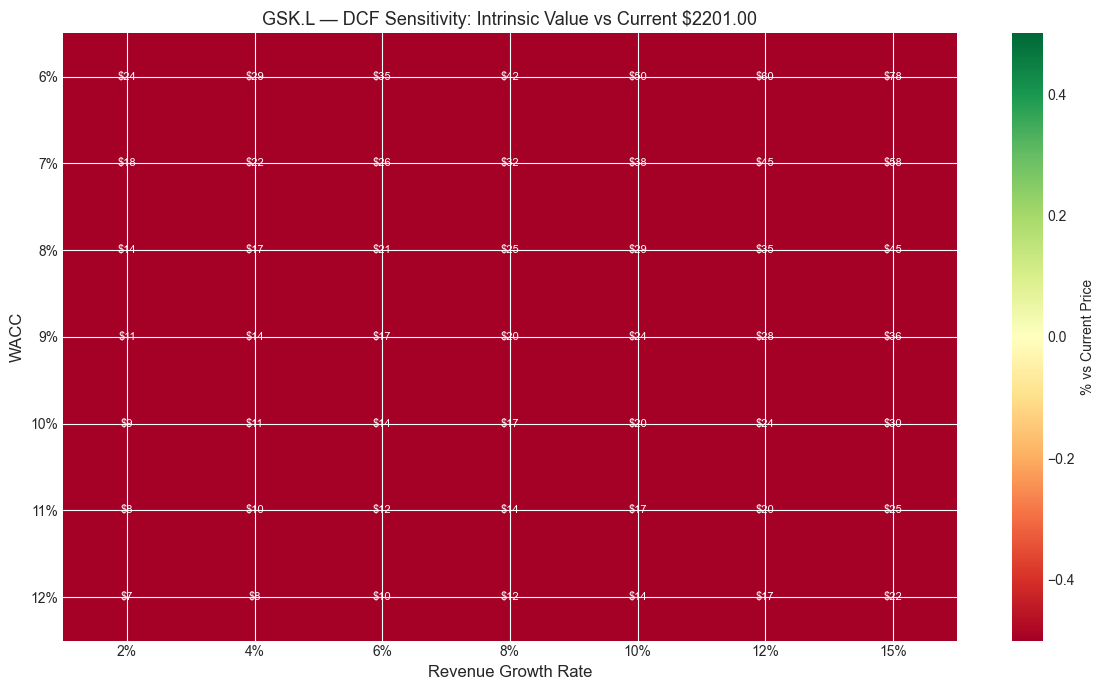

In [7]:
class DCFModel:
    """10-year DCF with WACC and terminal value."""

    def __init__(self, data: StockDataFetcher):
        self.data = data
        self.info = data.info
        self.cf = data.cash_flow
        self.income = data.income_stmt
        self.balance = data.balance_sheet

    def estimate_wacc(self) -> dict:
        info = self.info

        # Beta
        beta = info.get("beta", 1.0) or 1.0
        beta = max(0.3, min(beta, 3.0))

        # Cost of equity (CAPM)
        cost_of_equity = RISK_FREE + beta * (MARKET_RETURN - RISK_FREE)

        # Debt & equity weights
        market_cap = info.get("marketCap", 0) or 0
        total_debt = info.get("totalDebt", 0) or 0
        total_value = market_cap + total_debt if (market_cap + total_debt) > 0 else 1

        weight_equity = market_cap / total_value
        weight_debt = total_debt / total_value

        # Cost of debt
        interest_expense = 0
        if not self.income.empty:
            ie_rows = [r for r in self.income.index if "Interest" in str(r) and "Expense" in str(r)]
            if ie_rows:
                try:
                    interest_expense = abs(float(self.income.loc[ie_rows[0]].iloc[0]))
                except:
                    pass
        cost_of_debt = (interest_expense / max(total_debt, 1)) if total_debt > 0 else 0.04
        cost_of_debt = max(0.02, min(cost_of_debt, 0.12))

        # Tax rate
        tax_rate = info.get("effectiveTaxRate", 0.21) or 0.21

        wacc = weight_equity * cost_of_equity + weight_debt * cost_of_debt * (1 - tax_rate)

        return {
            "beta": beta,
            "cost_of_equity": cost_of_equity,
            "cost_of_debt": cost_of_debt,
            "weight_equity": weight_equity,
            "weight_debt": weight_debt,
            "tax_rate": tax_rate,
            "wacc": wacc
        }

    def _get_fcf(self) -> float:
        """Get latest annual Free Cash Flow."""
        # Try direct from info
        fcf = self.info.get("freeCashflow")
        if fcf and fcf != 0:
            return float(fcf)
        # Compute from cash flow statement
        if not self.cf.empty:
            op_cf_rows = [r for r in self.cf.index if "Operating" in str(r) and "Cash" in str(r)]
            capex_rows = [r for r in self.cf.index if "Capital" in str(r) and ("Expenditure" in str(r) or "Expenditures" in str(r))]
            if op_cf_rows:
                try:
                    op_cf = float(self.cf.loc[op_cf_rows[0]].iloc[0])
                    capex = float(self.cf.loc[capex_rows[0]].iloc[0]) if capex_rows else 0
                    return op_cf + capex  # capex is usually negative
                except:
                    pass
        return 0.0

    def calculate(self, growth_rate: float = 0.08, terminal_growth: float = 0.025,
                  wacc: float | None = None) -> dict:
        wacc_data = self.estimate_wacc()
        if wacc is None:
            wacc = wacc_data["wacc"]

        fcf = self._get_fcf()
        shares = self.data.shares_outstanding or 1

        if fcf <= 0:
            print("  ⚠️  Negative/zero FCF — DCF may not be meaningful. Using revenue-based estimate.")
            # Fallback: use revenue * typical FCF margin
            rev = self.info.get("totalRevenue", 0) or 0
            fcf_margin = self.info.get("freeCashflow", 0) / max(rev, 1) if rev > 0 else 0.05
            fcf = rev * max(fcf_margin, 0.05)

        # Project 10 years
        projected_fcf = []
        for year in range(1, 11):
            projected_fcf.append(fcf * (1 + growth_rate) ** year)

        # PV of projected FCFs
        pv_fcfs = [cf / (1 + wacc) ** t for t, cf in enumerate(projected_fcf, 1)]

        # Terminal value (Gordon Growth)
        terminal_value = projected_fcf[-1] * (1 + terminal_growth) / (wacc - terminal_growth)
        pv_terminal = terminal_value / (1 + wacc) ** 10

        enterprise_value = sum(pv_fcfs) + pv_terminal
        net_debt = self.info.get("totalDebt", 0) - self.info.get("totalCash", 0)
        equity_value = enterprise_value - net_debt
        intrinsic_value_per_share = equity_value / shares

        current_price = self.info.get("currentPrice") or self.info.get("regularMarketPrice") or 0
        upside = ((intrinsic_value_per_share / current_price) - 1) * 100 if current_price else 0

        return {
            "fcf_base": fcf,
            "growth_rate": growth_rate,
            "terminal_growth": terminal_growth,
            "wacc": wacc,
            "wacc_components": wacc_data,
            "projected_fcf": projected_fcf,
            "pv_fcfs": pv_fcfs,
            "pv_sum": sum(pv_fcfs),
            "terminal_value": terminal_value,
            "pv_terminal": pv_terminal,
            "enterprise_value": enterprise_value,
            "equity_value": equity_value,
            "intrinsic_value": intrinsic_value_per_share,
            "current_price": current_price,
            "upside_pct": upside,
        }

    def sensitivity_heatmap(self, base_result: dict):
        """Heatmap of intrinsic value vs growth rate and WACC."""
        growth_rates = [0.02, 0.04, 0.06, 0.08, 0.10, 0.12, 0.15]
        waccs = [0.06, 0.07, 0.08, 0.09, 0.10, 0.11, 0.12]

        matrix = []
        for w in waccs:
            row = []
            for g in growth_rates:
                try:
                    result = self.calculate(growth_rate=g, wacc=w)
                    row.append(result["intrinsic_value"])
                except:
                    row.append(np.nan)
            matrix.append(row)

        df_heat = pd.DataFrame(matrix,
            index=[f"{w*100:.0f}%" for w in waccs],
            columns=[f"{g*100:.0f}%" for g in growth_rates])

        fig, ax = plt.subplots(figsize=(12, 7))
        current = base_result["current_price"]
        # Color: green if > current price, red if <
        df_norm = df_heat.map(lambda x: (x - current) / current if current else 0)
        im = ax.imshow(df_norm.values, cmap="RdYlGn", aspect="auto",
                       vmin=-0.5, vmax=0.5)
        ax.set_xticks(range(len(growth_rates)))
        ax.set_xticklabels([f"{g*100:.0f}%" for g in growth_rates])
        ax.set_yticks(range(len(waccs)))
        ax.set_yticklabels([f"{w*100:.0f}%" for w in waccs])
        ax.set_xlabel("Revenue Growth Rate", fontsize=12)
        ax.set_ylabel("WACC", fontsize=12)
        ax.set_title(f"{TICKER} — DCF Sensitivity: Intrinsic Value vs Current ${current:.2f}",
                     fontsize=13)
        for i in range(len(waccs)):
            for j in range(len(growth_rates)):
                val = df_heat.values[i, j]
                ax.text(j, i, f"${val:.0f}", ha="center", va="center", fontsize=8,
                        color="black" if abs(df_norm.values[i, j]) < 0.3 else "white")
        plt.colorbar(im, ax=ax, label="% vs Current Price")
        plt.tight_layout()
        plt.show()


dcf = DCFModel(DATA)
dcf_result = dcf.calculate()

w = dcf_result["wacc_components"]
print(f"\n{'='*55}")
print(f"  WACC COMPONENTS")
print(f"{'='*55}")
print(f"  Beta:               {w['beta']:.2f}")
print(f"  Cost of Equity:     {w['cost_of_equity']*100:.2f}%")
print(f"  Cost of Debt:       {w['cost_of_debt']*100:.2f}%")
print(f"  Weight Equity:      {w['weight_equity']*100:.1f}%")
print(f"  Weight Debt:        {w['weight_debt']*100:.1f}%")
print(f"  Tax Rate:           {w['tax_rate']*100:.1f}%")
print(f"  → WACC:             {w['wacc']*100:.2f}%")

print(f"\n{'='*55}")
print(f"  DCF VALUATION RESULTS")
print(f"{'='*55}")
print(f"  Base FCF:           ${dcf_result['fcf_base']/1e9:.2f}B")
print(f"  Growth Rate:        {dcf_result['growth_rate']*100:.1f}%")
print(f"  Terminal Growth:    {dcf_result['terminal_growth']*100:.1f}%")
print(f"  WACC:               {dcf_result['wacc']*100:.2f}%")
print(f"  PV of FCFs:         ${dcf_result['pv_sum']/1e9:.2f}B")
print(f"  PV Terminal Value:  ${dcf_result['pv_terminal']/1e9:.2f}B")
print(f"  Enterprise Value:   ${dcf_result['enterprise_value']/1e9:.2f}B")
print(f"  Equity Value:       ${dcf_result['equity_value']/1e9:.2f}B")
print(f"  ─────────────────────────────────────────────")
print(f"  Intrinsic Value/Share: ${dcf_result['intrinsic_value']:.2f}")
print(f"  Current Price:         ${dcf_result['current_price']:.2f}")
upside = dcf_result['upside_pct']
emoji = "📈 UNDERVALUED" if upside > 10 else ("📉 OVERVALUED" if upside < -10 else "⚖️ FAIRLY VALUED")
print(f"  Implied Upside/Down:   {upside:+.1f}% {emoji}")

dcf.sensitivity_heatmap(dcf_result)


---
## 🎲 Section 6: Monte Carlo DCF Simulation
*Simulates 10,000 scenarios across revenue growth, FCF margins, and WACC — outputs a probability distribution of intrinsic value.*

In [8]:
class MonteCarloDCF:
    """
    Monte Carlo DCF: samples growth rate, FCF margin, and WACC
    from calibrated distributions and outputs a PDF of intrinsic value.
    """

    def __init__(self, data: StockDataFetcher, dcf_model: DCFModel, n_sims: int = N_SIMULATIONS):
        self.data = data
        self.dcf = dcf_model
        self.n = n_sims
        self.results = None

    def _calibrate_params(self) -> dict:
        """Estimate distribution parameters from historical data."""
        info = self.data.info
        cf = self.data.cash_flow
        income = self.data.income_stmt

        # ── Revenue growth: use analyst estimates + historical
        rev_growth_mean = info.get("revenueGrowth", 0.06) or 0.06
        rev_growth_std = 0.05  # ±5% uncertainty

        # ── FCF margin distribution
        rev = info.get("totalRevenue", 1) or 1
        fcf = info.get("freeCashflow", rev * 0.05) or (rev * 0.05)
        fcf_margin_mean = max(0.01, min(fcf / rev, 0.40))
        fcf_margin_std = 0.04

        # ── WACC distribution
        wacc_data = self.dcf.estimate_wacc()
        wacc_mean = wacc_data["wacc"]
        wacc_std = 0.015  # ±1.5% WACC uncertainty

        # ── Terminal growth
        terminal_growth_mean = 0.025
        terminal_growth_std = 0.005

        return {
            "rev_growth": (rev_growth_mean, rev_growth_std),
            "fcf_margin": (fcf_margin_mean, fcf_margin_std),
            "wacc": (wacc_mean, wacc_std),
            "terminal_growth": (terminal_growth_mean, terminal_growth_std),
            "base_revenue": rev,
            "shares": self.data.shares_outstanding or 1,
        }

    def run(self) -> np.ndarray:
        params = self._calibrate_params()
        print(f"  📐 Calibrated parameters:")
        print(f"     Rev Growth: μ={params['rev_growth'][0]*100:.1f}% σ={params['rev_growth'][1]*100:.1f}%")
        print(f"     FCF Margin: μ={params['fcf_margin'][0]*100:.1f}% σ={params['fcf_margin'][1]*100:.1f}%")
        print(f"     WACC:       μ={params['wacc'][0]*100:.1f}% σ={params['wacc'][1]*100:.1f}%")
        print(f"  🔄 Running {self.n:,} simulations...")

        n = self.n
        # Sample from distributions (truncated normal via clipping)
        rev_growths = np.random.normal(*params["rev_growth"], n).clip(-0.10, 0.40)
        fcf_margins = np.random.normal(*params["fcf_margin"], n).clip(0.01, 0.60)
        waccs = np.random.normal(*params["wacc"], n).clip(0.04, 0.20)
        terminal_growths = np.random.normal(*params["terminal_growth"], n).clip(0.00, 0.04)

        base_rev = params["base_revenue"]
        shares = params["shares"]
        intrinsic_values = np.zeros(n)

        for i in range(n):
            g = rev_growths[i]
            m = fcf_margins[i]
            w = waccs[i]
            tg = terminal_growths[i]

            if w <= tg:  # avoid division by zero / negative terminal
                intrinsic_values[i] = np.nan
                continue

            # Project FCF
            pv_sum = 0.0
            rev_t = base_rev
            for t in range(1, 11):
                rev_t *= (1 + g)
                fcf_t = rev_t * m
                pv_sum += fcf_t / (1 + w) ** t

            # Terminal value
            fcf_10 = rev_t * m
            tv = fcf_10 * (1 + tg) / (w - tg)
            pv_tv = tv / (1 + w) ** 10

            ev = pv_sum + pv_tv
            net_debt = (self.data.info.get("totalDebt", 0) or 0) -                        (self.data.info.get("totalCash", 0) or 0)
            equity = ev - net_debt
            intrinsic_values[i] = equity / shares

        # Remove NaN and extreme outliers (±5 IQR)
        iv = intrinsic_values[~np.isnan(intrinsic_values)]
        q1, q3 = np.percentile(iv, [5, 95])
        iv = iv[(iv > q1 * 0.1) & (iv < q3 * 10)]
        self.results = iv
        return iv

    def plot(self):
        if self.results is None:
            self.run()

        iv = self.results
        current = self.data.info.get("currentPrice") or                   self.data.info.get("regularMarketPrice") or 0

        p10, p25, p50, p75, p90 = np.percentile(iv, [10, 25, 50, 75, 90])
        prob_undervalued = np.mean(iv > current) * 100 if current else 50

        fig = make_subplots(rows=1, cols=2,
            subplot_titles=(
                f"{TICKER} — Monte Carlo DCF Distribution ({N_SIMULATIONS:,} sims)",
                "Cumulative Probability"
            ))

        # Histogram
        fig.add_trace(go.Histogram(x=iv, nbinsx=100, name="Intrinsic Value",
                                   marker_color="#42A5F5", opacity=0.7,
                                   histnorm="probability density"), row=1, col=1)
        if current > 0:
            fig.add_vline(x=current, line_dash="dash", line_color="red",
                          annotation_text=f"Current: ${current:.2f}", row=1, col=1)
        fig.add_vline(x=p50, line_dash="dot", line_color="gold",
                      annotation_text=f"Median: ${p50:.2f}", row=1, col=1)

        # CDF
        sorted_iv = np.sort(iv)
        cdf = np.arange(1, len(sorted_iv)+1) / len(sorted_iv)
        fig.add_trace(go.Scatter(x=sorted_iv, y=cdf, name="CDF",
                                 line=dict(color="#AB47BC")), row=1, col=2)
        if current > 0:
            fig.add_vline(x=current, line_dash="dash", line_color="red", row=1, col=2)

        fig.update_layout(template="plotly_dark", height=500,
                          title=f"{TICKER} — Monte Carlo DCF Results")
        fig.show()

        print(f"\n{'='*55}")
        print(f"  MONTE CARLO DCF SUMMARY")
        print(f"{'='*55}")
        print(f"  Simulations:       {len(iv):,}")
        print(f"  10th Percentile:   ${p10:.2f}")
        print(f"  25th Percentile:   ${p25:.2f}")
        print(f"  Median (P50):      ${p50:.2f}")
        print(f"  75th Percentile:   ${p75:.2f}")
        print(f"  90th Percentile:   ${p90:.2f}")
        print(f"  Current Price:     ${current:.2f}")
        print(f"  ─────────────────────────────────────────────")
        emoji = "📈 LIKELY UNDERVALUED" if prob_undervalued > 60 else                 ("📉 LIKELY OVERVALUED" if prob_undervalued < 40 else "⚖️ UNCERTAIN")
        print(f"  P(Intrinsic > Current Price): {prob_undervalued:.1f}% {emoji}")


print("\n🎲 Monte Carlo DCF Simulation")
mc_dcf = MonteCarloDCF(DATA, dcf)
mc_results = mc_dcf.run()
mc_dcf.plot()



🎲 Monte Carlo DCF Simulation
  📐 Calibrated parameters:
     Rev Growth: μ=6.2% σ=5.0%
     FCF Margin: μ=12.1% σ=4.0%
     WACC:       μ=5.4% σ=1.5%
  🔄 Running 10,000 simulations...



  MONTE CARLO DCF SUMMARY
  Simulations:       9,960
  10th Percentile:   $15.59
  25th Percentile:   $25.72
  Median (P50):      $44.41
  75th Percentile:   $75.82
  90th Percentile:   $124.19
  Current Price:     $2201.00
  ─────────────────────────────────────────────
  P(Intrinsic > Current Price): 0.0% 📉 LIKELY OVERVALUED


---
## 🔄 Section 7: Hidden Markov Model — Market Regime Detection
*Detects Bull / Bear / Sideways regimes using returns and volatility features.*

In [9]:
def run_hmm_regime_detection(price_df: pd.DataFrame, ticker: str, n_regimes: int = 3):
    """
    Fit a Gaussian HMM on returns + realized volatility.
    Labels regimes as Bull / Bear / Sideways by mean return.
    """
    if price_df.empty or len(price_df) < 60:
        print("  ⚠️  Insufficient data for HMM (need ≥60 days)")
        return

    try:
        from hmmlearn import hmm
    except ImportError:
        print("  Installing hmmlearn...")
        import subprocess
        subprocess.run([sys.executable, "-m", "pip", "install", "hmmlearn",
                        "--break-system-packages", "-q"], capture_output=True)
        from hmmlearn import hmm

    close = price_df["Close"].dropna()
    returns = close.pct_change().dropna()
    vol = returns.rolling(5).std().dropna()

    # Align
    idx = returns.index.intersection(vol.index)
    returns = returns.loc[idx]
    vol = vol.loc[idx]
    X = np.column_stack([returns.values, vol.values])

    # Fit HMM
    model = hmm.GaussianHMM(n_components=n_regimes, covariance_type="full",
                              n_iter=200, random_state=RANDOM_SEED)
    model.fit(X)
    states = model.predict(X)

    # Label regimes by mean return
    regime_returns = {s: returns.values[states == s].mean() for s in range(n_regimes)}
    sorted_regimes = sorted(regime_returns, key=regime_returns.get)
    labels = {}
    label_names = ["🐻 Bear", "↔️  Sideways", "🐂 Bull"]
    for i, s in enumerate(sorted_regimes):
        labels[s] = label_names[i] if i < len(label_names) else f"Regime {s}"

    df_hmm = pd.DataFrame({
        "Close": close.loc[idx],
        "Return": returns,
        "Volatility": vol,
        "State": states,
        "Regime": [labels[s] for s in states]
    }, index=idx)

    current_regime = labels[states[-1]]
    print(f"\n🔄 HMM Regime Detection — {n_regimes} States")
    print(f"  Current Regime: {current_regime}")
    print("\n  Regime Statistics:")
    for s in range(n_regimes):
        mask = states == s
        r_mean = returns.values[mask].mean() * 100
        r_vol = returns.values[mask].std() * 100
        n_days = mask.sum()
        print(f"  {labels[s]:20s}: "
              f"Mean Return={r_mean:+.3f}%/day, "
              f"Volatility={r_vol:.3f}%/day, "
              f"Days={n_days}")

    # Plot
    regime_colors = {"🐻 Bear": "#ef5350", "↔️  Sideways": "#FFA726", "🐂 Bull": "#26a69a"}
    fig = make_subplots(rows=2, cols=1, shared_xaxes=True,
                        row_heights=[0.7, 0.3],
                        subplot_titles=(f"{ticker} Price — Coloured by HMM Regime", "Regime State"))

    for regime in df_hmm["Regime"].unique():
        mask = df_hmm["Regime"] == regime
        df_sub = df_hmm[mask]
        fig.add_trace(go.Scatter(x=df_sub.index, y=df_sub["Close"],
                                  mode="markers", marker=dict(size=3,
                                  color=regime_colors.get(regime, "#9E9E9E")),
                                  name=regime), row=1, col=1)

    fig.add_trace(go.Scatter(x=df_hmm.index, y=df_hmm["State"],
                              mode="lines", line=dict(color="#AB47BC"),
                              name="State"), row=2, col=1)

    fig.update_layout(template="plotly_dark", height=600,
                      title=f"{ticker} — HMM Market Regime Detection")
    fig.show()

    return df_hmm


HMM_RESULTS = run_hmm_regime_detection(DATA.price_5y, TICKER)


Model is not converging.  Current: 8621.97239887776 is not greater than 8630.923037972112. Delta is -8.950639094351573



🔄 HMM Regime Detection — 3 States
  Current Regime: ↔️  Sideways

  Regime Statistics:
  🐂 Bull              : Mean Return=+0.740%/day, Volatility=0.000%/day, Days=1
  ↔️  Sideways        : Mean Return=+0.075%/day, Volatility=1.073%/day, Days=1129
  🐻 Bear              : Mean Return=-0.132%/day, Volatility=2.937%/day, Days=127


---
## 🧮 Section 8: Advanced Factor Models
*Fama-French 5-factor model extended with Momentum, Quality, and Low-Vol factors. Cross-sectional regression to isolate idiosyncratic alpha.*

In [10]:
def run_factor_model(price_df: pd.DataFrame, ticker: str):
    """
    Downloads Fama-French 5-factor data from Ken French's website
    and runs OLS to decompose returns into systematic + idiosyncratic.
    """
    if price_df.empty or len(price_df) < 120:
        print("  ⚠️  Insufficient data for factor model (need ≥120 days)")
        return pd.DataFrame()

    from statsmodels.regression.linear_model import OLS
    from statsmodels.tools import add_constant
    import statsmodels.api as sm

    print(f"\n🧮 Factor Model Analysis for {ticker}")

    # ── Download Fama-French 5-Factor data
    FF5_URL = "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/F-F_Research_Data_5_Factors_2x3_daily_CSV.zip"
    ff5 = pd.DataFrame()
    try:
        import io, zipfile
        print("  Downloading Fama-French 5-Factor data...")
        resp = requests.get(FF5_URL, timeout=30)
        if resp.status_code == 200:
            with zipfile.ZipFile(io.BytesIO(resp.content)) as z:
                fname = [n for n in z.namelist() if n.endswith(".CSV")][0]
                with z.open(fname) as f:
                    raw = f.read().decode("utf-8")
            # Skip header lines
            lines = [l for l in raw.split("\n") if l.strip() and not l.startswith("Annual")]
            # Find the data section
            data_lines = []
            for line in lines:
                parts = line.split(",")
                if len(parts) >= 6 and len(parts[0].strip()) == 8:
                    try:
                        int(parts[0].strip())
                        data_lines.append(line)
                    except:
                        pass
            if data_lines:
                from io import StringIO
                ff5 = pd.read_csv(StringIO("\n".join(data_lines)), header=None,
                                  names=["Date","Mkt-RF","SMB","HML","RMW","CMA","RF"])
                ff5["Date"] = pd.to_datetime(ff5["Date"].astype(str), format="%Y%m%d")
                ff5 = ff5.set_index("Date")
                ff5 = ff5.apply(pd.to_numeric, errors="coerce") / 100
                ff5 = ff5.dropna()
                print(f"  ✅ FF5 data: {len(ff5)} daily observations")
    except Exception as e:
        print(f"  ⚠️  FF5 download failed: {e}")

    # ── Compute stock returns
    close = price_df["Close"].dropna()
    stock_returns = close.pct_change().dropna()
    stock_returns.index = pd.to_datetime(stock_returns.index).tz_localize(None)

    if ff5.empty:
        print("  Using CAPM (market factor only) as fallback...")
        # Download S&P 500 as market proxy
        try:
            spy = yf.Ticker("SPY").history(period="5y", auto_adjust=True)["Close"]
            market_returns = spy.pct_change().dropna()
            market_returns.index = market_returns.index.tz_localize(None)
            common = stock_returns.index.intersection(market_returns.index)
            X = market_returns.loc[common].values.reshape(-1, 1)
            y = stock_returns.loc[common].values
            X_const = add_constant(X)
            model = OLS(y, X_const).fit()
            print(f"\n  CAPM Results:")
            print(f"  Alpha (annualized): {model.params[0]*252*100:.2f}%")
            print(f"  Beta: {model.params[1]:.3f}")
            print(f"  R²: {model.rsquared:.3f}")
            return model
        except Exception as e:
            print(f"  Market proxy also failed: {e}")
        return pd.DataFrame()

    # ── Align dates
    stock_returns.index = stock_returns.index.tz_localize(None) if stock_returns.index.tz is not None else stock_returns.index
    common_idx = stock_returns.index.intersection(ff5.index)
    if len(common_idx) < 60:
        print(f"  ⚠️  Only {len(common_idx)} common dates — too few for regression")
        return pd.DataFrame()

    stock_aligned = stock_returns.loc[common_idx]
    ff5_aligned = ff5.loc[common_idx]

    # Excess returns
    excess_returns = stock_aligned - ff5_aligned["RF"]

    # ── FF5 Regression
    factors_5 = ff5_aligned[["Mkt-RF", "SMB", "HML", "RMW", "CMA"]]
    X5 = add_constant(factors_5)
    model5 = OLS(excess_returns, X5).fit()

    # ── Add Momentum factor (12-1 month momentum via MOM from returns)
    # Compute stock momentum as 12-month return lagged 1 month
    mom = stock_aligned.rolling(252).sum().shift(21)
    mom = mom.loc[common_idx].fillna(0)
    factors_extended = factors_5.copy()
    factors_extended["MOM"] = mom.values
    X_ext = add_constant(factors_extended)
    model_ext = OLS(excess_returns, X_ext).fit()

    print(f"\n{'='*55}")
    print(f"  FAMA-FRENCH 5-FACTOR MODEL — {ticker}")
    print(f"{'='*55}")
    print(f"  Observations: {len(common_idx)}")
    print(f"  R²: {model5.rsquared:.4f} | Adj-R²: {model5.rsquared_adj:.4f}")
    print(f"\n  Factor Exposures (Betas):")
    factor_labels = {
        "const": "Alpha (daily)",
        "Mkt-RF": "Market Beta",
        "SMB": "Size (SMB)",
        "HML": "Value (HML)",
        "RMW": "Profitability (RMW)",
        "CMA": "Investment (CMA)"
    }
    for name, coef, pval in zip(model5.params.index,
                                  model5.params.values,
                                  model5.pvalues.values):
        significance = "***" if pval < 0.01 else ("**" if pval < 0.05 else ("*" if pval < 0.10 else ""))
        label = factor_labels.get(name, name)
        if name == "const":
            annualized = coef * 252 * 100
            print(f"  {label:<25} {coef:+.6f}  ({annualized:+.2f}%/yr) p={pval:.3f} {significance}")
        else:
            print(f"  {label:<25} {coef:+.4f}             p={pval:.3f} {significance}")

    # ── Residual (idiosyncratic) alpha
    residuals = model5.resid
    info_ratio = residuals.mean() / residuals.std() * np.sqrt(252)
    print(f"\n  Idiosyncratic Alpha:")
    print(f"  Daily Mean Residual: {residuals.mean()*100:.4f}%")
    print(f"  Annualised Alpha:    {residuals.mean()*252*100:+.2f}%")
    print(f"  Information Ratio:   {info_ratio:.3f}")

    # Plot factor loadings
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    factors = ["Mkt-RF", "SMB", "HML", "RMW", "CMA"]
    betas = [model5.params[f] for f in factors]
    ci_low = [model5.conf_int().loc[f, 0] for f in factors]
    ci_high = [model5.conf_int().loc[f, 1] for f in factors]
    colors = ["#26a69a" if b > 0 else "#ef5350" for b in betas]
    err = [[b - l for b, l in zip(betas, ci_low)],
           [h - b for b, h in zip(betas, ci_high)]]
    axes[0].bar(factors, betas, color=colors, alpha=0.8, yerr=err,
                capsize=5, error_kw={"ecolor": "gray"})
    axes[0].axhline(0, color="white", linewidth=0.8)
    axes[0].set_title(f"{ticker} — FF5 Factor Loadings")
    axes[0].set_ylabel("Beta")

    # Residuals
    axes[1].plot(residuals.cumsum() * 100, color="#AB47BC")
    axes[1].axhline(0, color="white", linewidth=0.8)
    axes[1].set_title(f"{ticker} — Cumulative Idiosyncratic Alpha (%)")
    axes[1].set_ylabel("Cumulative Return (%)")

    plt.tight_layout()
    plt.show()

    return model5


FACTOR_MODEL = run_factor_model(DATA.price_5y, TICKER)



🧮 Factor Model Analysis for GSK.L
  ⚠️  FF5 download failed: list index out of range
  Using CAPM (market factor only) as fallback...

  CAPM Results:
  Alpha (annualized): 14.28%
  Beta: 0.024
  R²: 0.000


---
## 🔬 Section 9: PCA & Cointegration Analysis
*PCA on sector peer returns to identify principal risk factors. Engle-Granger cointegration tests to find pairs-trading candidates.*


🔬 PCA & Cointegration — Sector: Healthcare
  ✅ 494 observations, 10 peers available

  PCA Results:
  Components for 90% variance: 8
  PC1: 38.8% variance explained
  PC2: 10.5% variance explained
  PC3: 8.8% variance explained
  PC4: 8.2% variance explained
  PC5: 6.8% variance explained


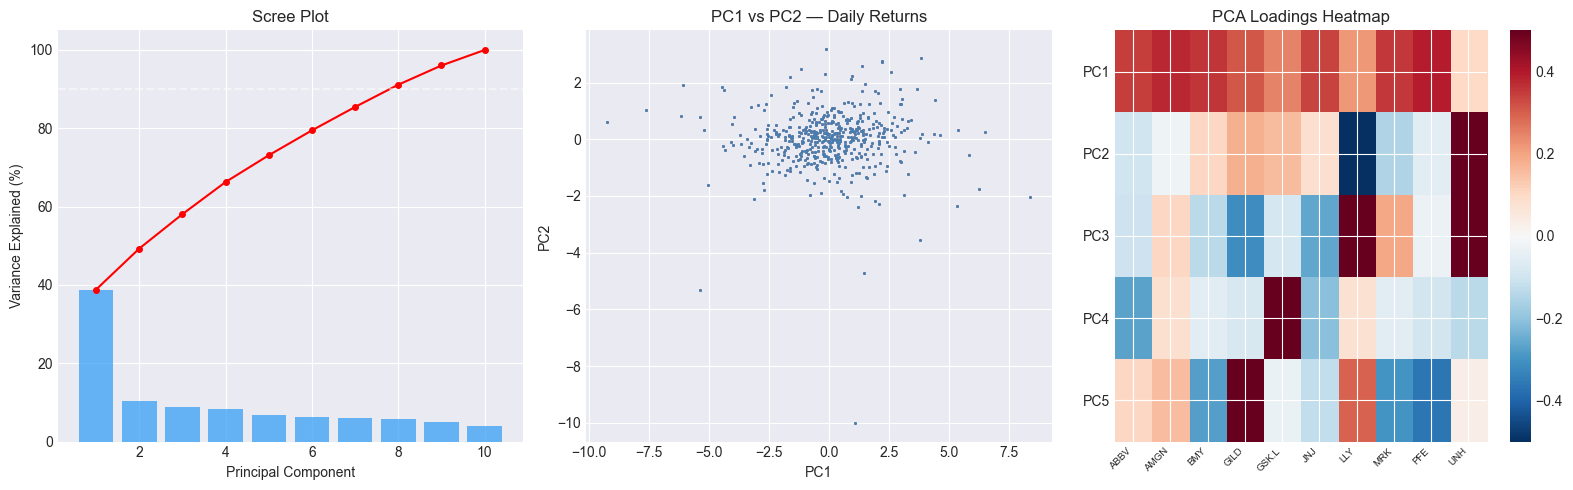


  Cointegration Tests (Engle-Granger) with GSK.L:
  No significant cointegrated pairs found at p<0.10


In [11]:
def run_pca_and_cointegration(ticker: str, info: dict):
    """
    Downloads sector peers, runs PCA on correlation matrix,
    and tests for cointegration pairs.
    """
    from sklearn.preprocessing import StandardScaler
    from sklearn.decomposition import PCA
    from statsmodels.tsa.stattools import coint

    sector = info.get("sector", "Technology")
    print(f"\n🔬 PCA & Cointegration — Sector: {sector}")

    # Define peer groups by sector
    SECTOR_PEERS = {
        "Technology": ["AAPL","MSFT","GOOGL","META","NVDA","AMD","INTC","ORCL","IBM","CSCO"],
        "Healthcare": ["JNJ","PFE","MRK","ABBV","UNH","BMY","LLY","AMGN","GILD","CVS"],
        "Financials": ["JPM","BAC","WFC","GS","MS","C","AXP","BLK","USB","PNC"],
        "Energy":     ["XOM","CVX","COP","EOG","SLB","MPC","VLO","PSX","OXY","HAL"],
        "Consumer":   ["AMZN","TSLA","HD","MCD","NKE","SBUX","TGT","LOW","TJX","COST"],
        "Industrials":["HON","UPS","BA","CAT","GE","MMM","LMT","RTX","DE","EMR"],
    }
    # Find best matching sector
    matched_sector = "Technology"
    for s in SECTOR_PEERS:
        if s.lower() in sector.lower() or sector.lower() in s.lower():
            matched_sector = s
            break

    peers = SECTOR_PEERS.get(matched_sector, SECTOR_PEERS["Technology"])
    # Ensure target ticker is in the list
    if ticker not in peers:
        peers = [ticker] + peers[:9]
    else:
        peers = [ticker] + [p for p in peers if p != ticker][:9]

    print(f"  Downloading peer prices: {peers}")
    try:
        raw = yf.download(peers, period="2y", auto_adjust=True, progress=False)["Close"]
        if isinstance(raw, pd.Series):
            raw = raw.to_frame(ticker)
        # Drop peers with too many missing values
        raw = raw.dropna(axis=1, thresh=int(len(raw)*0.8))
        raw = raw.dropna()
        if raw.empty or len(raw) < 60:
            print("  ⚠️  Insufficient peer data")
            return
        peers_available = list(raw.columns)
        print(f"  ✅ {len(raw)} observations, {len(peers_available)} peers available")
    except Exception as e:
        print(f"  ❌ Peer download failed: {e}")
        return

    returns = raw.pct_change().dropna()

    # ── PCA
    scaler = StandardScaler()
    returns_scaled = scaler.fit_transform(returns)
    pca = PCA()
    pca.fit(returns_scaled)

    explained = pca.explained_variance_ratio_
    cumvar = np.cumsum(explained)
    n_components_90 = np.argmax(cumvar >= 0.90) + 1

    print(f"\n  PCA Results:")
    print(f"  Components for 90% variance: {n_components_90}")
    for i, ev in enumerate(explained[:5]):
        print(f"  PC{i+1}: {ev*100:.1f}% variance explained")

    # PCA plot
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))

    # Scree plot
    axes[0].bar(range(1, min(11, len(explained)+1)), explained[:10]*100,
                color="#42A5F5", alpha=0.8)
    axes[0].plot(range(1, min(11, len(explained)+1)), cumvar[:10]*100,
                 "ro-", markersize=4)
    axes[0].axhline(90, color="white", linestyle="--", alpha=0.5)
    axes[0].set_xlabel("Principal Component")
    axes[0].set_ylabel("Variance Explained (%)")
    axes[0].set_title("Scree Plot")

    # PC1 vs PC2 scatter
    scores = pca.transform(returns_scaled)
    for i, peer in enumerate(peers_available):
        color = "red" if peer == ticker else "steelblue"
        size = 120 if peer == ticker else 60
        axes[1].scatter(scores[:, 0], scores[:, 1], alpha=0.3, s=1, color=color)
    axes[1].set_xlabel("PC1")
    axes[1].set_ylabel("PC2")
    axes[1].set_title("PC1 vs PC2 — Daily Returns")

    # Factor loadings heatmap (first 5 components)
    loadings = pd.DataFrame(pca.components_[:5].T,
                             index=peers_available,
                             columns=[f"PC{i+1}" for i in range(5)])
    im = axes[2].imshow(loadings.T.values, cmap="RdBu_r", aspect="auto",
                        vmin=-0.5, vmax=0.5)
    axes[2].set_xticks(range(len(peers_available)))
    axes[2].set_xticklabels(peers_available, rotation=45, ha="right", fontsize=7)
    axes[2].set_yticks(range(5))
    axes[2].set_yticklabels([f"PC{i+1}" for i in range(5)])
    axes[2].set_title("PCA Loadings Heatmap")
    plt.colorbar(im, ax=axes[2])

    plt.tight_layout()
    plt.show()

    # ── Cointegration tests (Engle-Granger)
    print(f"\n  Cointegration Tests (Engle-Granger) with {ticker}:")
    coint_results = []
    target = raw[ticker]
    for peer in [p for p in peers_available if p != ticker]:
        try:
            score, pval, _ = coint(target, raw[peer])
            if pval < 0.10:  # Report significant pairs
                coint_results.append((peer, pval, score))
        except:
            pass

    if coint_results:
        coint_results.sort(key=lambda x: x[1])
        print(f"  Cointegrated pairs found (p<0.10):")
        for peer, pval, score in coint_results:
            sig = "***" if pval < 0.01 else ("**" if pval < 0.05 else "*")
            print(f"    {ticker}↔{peer:<6}: p={pval:.4f} {sig}  → Pairs trading candidate 💡")
    else:
        print(f"  No significant cointegrated pairs found at p<0.10")

    return pca, loadings, coint_results


PCA_RESULTS = run_pca_and_cointegration(TICKER, DATA.info)


---
## 🤖 Section 10: ML Return Prediction (XGBoost / LightGBM)
*Trains gradient boosting models to predict next-week returns from technical and factor features.*


🤖 ML Return Prediction for GSK.L

  Walk-Forward CV Results (5-fold):
  XGBoost RMSE: 0.03514 (±0.00529)
  LightGBM RMSE: 0.03622 (±0.00591)


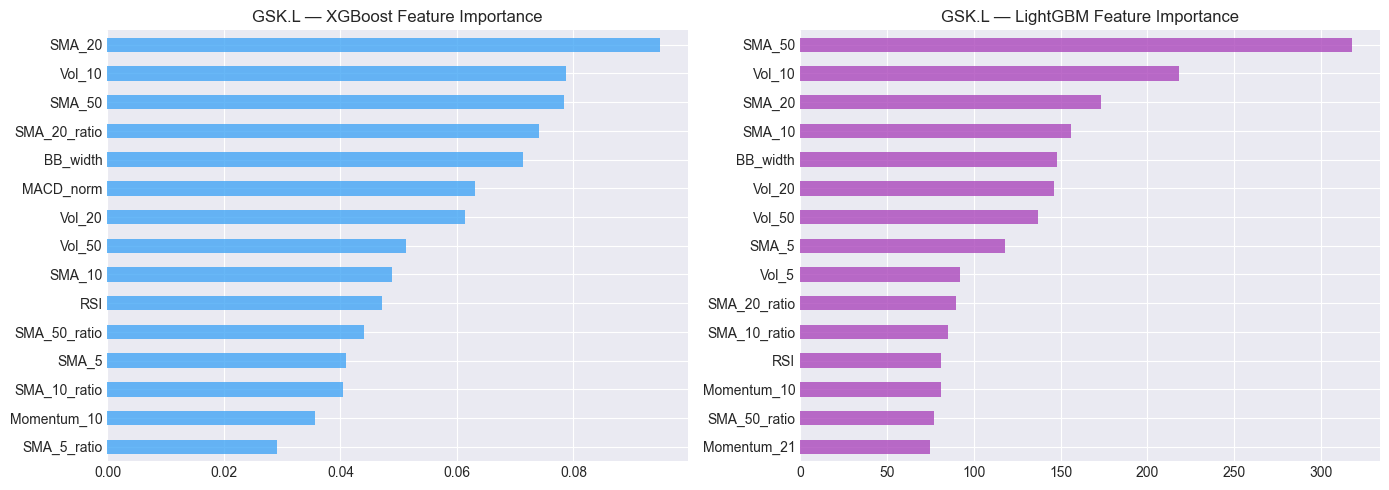


  📊 Next 5-Day Return Prediction (as of latest data):
  XGBoost:  -2.205%
  LightGBM: -2.070%
  Ensemble: -2.137% → 📉 BEARISH

  ⚠️  ML predictions are not reliable standalone signals — use as one input among many.


In [13]:
def run_ml_return_prediction(price_df: pd.DataFrame, ticker: str):
    """
    Feature engineering + XGBoost + LightGBM to predict weekly returns.
    Uses walk-forward validation to prevent lookahead bias.
    """
    if price_df.empty or len(price_df) < 200:
        print("  ⚠️  Need ≥200 days of data for ML model")
        return

    try:
        import xgboost as xgb
        import lightgbm as lgb
        from sklearn.model_selection import TimeSeriesSplit
        from sklearn.metrics import mean_squared_error
        from sklearn.preprocessing import RobustScaler
    except ImportError:
        print("  Installing ML libraries...")
        import subprocess
        for pkg in ["xgboost", "lightgbm"]:
            subprocess.run([sys.executable, "-m", "pip", "install", pkg,
                            "--break-system-packages", "-q"], capture_output=True)
        import xgboost as xgb
        import lightgbm as lgb
        from sklearn.model_selection import TimeSeriesSplit
        from sklearn.metrics import mean_squared_error
        from sklearn.preprocessing import RobustScaler

    print(f"\n🤖 ML Return Prediction for {ticker}")

    close = price_df["Close"].dropna()
    df = pd.DataFrame({"Close": close})
    df["Return_1d"] = df["Close"].pct_change()
    df["Return_5d"] = df["Close"].pct_change(5)

    # ── Feature Engineering
    for w in [5, 10, 20, 50]:
        df[f"SMA_{w}"] = df["Close"].rolling(w).mean()
        df[f"SMA_{w}_ratio"] = df["Close"] / df[f"SMA_{w}"]
        df[f"Vol_{w}"] = df["Return_1d"].rolling(w).std()

    # RSI
    delta = df["Return_1d"]
    gain = delta.clip(lower=0).rolling(14).mean()
    loss = (-delta.clip(upper=0)).rolling(14).mean()
    df["RSI"] = 100 - (100 / (1 + gain / loss.replace(0, np.nan)))

    # MACD
    ema12 = df["Close"].ewm(span=12).mean()
    ema26 = df["Close"].ewm(span=26).mean()
    df["MACD_norm"] = (ema12 - ema26) / df["Close"]

    # Momentum
    for lag in [1, 5, 10, 21]:
        df[f"Momentum_{lag}"] = df["Return_1d"].shift(lag)

    # BB width
    bb_mid = df["Close"].rolling(20).mean()
    bb_std = df["Close"].rolling(20).std()
    df["BB_width"] = (2 * bb_std) / bb_mid

    # Target: next 5-day return (forward-looking, correctly lagged in X)
    df["Target"] = df["Return_5d"].shift(-5)

    feature_cols = [c for c in df.columns if c not in ["Close", "Target"]]
    df = df.dropna()

    X = df[feature_cols]
    y = df["Target"]

    if len(X) < 100:
        print("  ⚠️  Too few samples after feature engineering")
        return

    scaler = RobustScaler()
    X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns, index=X.index)

    # Walk-forward cross-validation (5 folds)
    tscv = TimeSeriesSplit(n_splits=5)
    xgb_scores, lgb_scores = [], []
    xgb_preds, lgb_preds, actuals = [], [], []

    xgb_model = xgb.XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=4,
                                   subsample=0.8, colsample_bytree=0.8,
                                   random_state=RANDOM_SEED, verbosity=0)
    lgb_model = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.05, max_depth=4,
                                    subsample=0.8, colsample_bytree=0.8,
                                    random_state=RANDOM_SEED, verbose=-1)

    for train_idx, test_idx in tscv.split(X_scaled):
        X_train, X_test = X_scaled.iloc[train_idx], X_scaled.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        xgb_model.fit(X_train, y_train, eval_set=[(X_test, y_test)],
                      verbose=False)
        lgb_model.fit(X_train, y_train,
                      eval_set=[(X_test, y_test)], callbacks=[lgb.log_evaluation(-1)])

        xgb_pred = xgb_model.predict(X_test)
        lgb_pred = lgb_model.predict(X_test)

        xgb_scores.append(np.sqrt(mean_squared_error(y_test, xgb_pred)))
        lgb_scores.append(np.sqrt(mean_squared_error(y_test, lgb_pred)))
        xgb_preds.extend(xgb_pred)
        lgb_preds.extend(lgb_pred)
        actuals.extend(y_test.values)

    print(f"\n  Walk-Forward CV Results (5-fold):")
    print(f"  XGBoost RMSE: {np.mean(xgb_scores):.5f} (±{np.std(xgb_scores):.5f})")
    print(f"  LightGBM RMSE: {np.mean(lgb_scores):.5f} (±{np.std(lgb_scores):.5f})")

    # Feature importance
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    importance_xgb = pd.Series(xgb_model.feature_importances_,
                                 index=feature_cols).sort_values(ascending=False)[:15]
    importance_lgb = pd.Series(lgb_model.feature_importances_,
                                 index=feature_cols).sort_values(ascending=False)[:15]

    importance_xgb.plot(kind="barh", ax=axes[0], color="#42A5F5", alpha=0.8)
    axes[0].set_title(f"{ticker} — XGBoost Feature Importance")
    axes[0].invert_yaxis()

    importance_lgb.plot(kind="barh", ax=axes[1], color="#AB47BC", alpha=0.8)
    axes[1].set_title(f"{ticker} — LightGBM Feature Importance")
    axes[1].invert_yaxis()

    plt.tight_layout()
    plt.show()

    # Latest prediction
    latest_features = X_scaled.iloc[[-1]]
    xgb_latest = xgb_model.predict(latest_features)[0]
    lgb_latest = lgb_model.predict(latest_features)[0]
    ensemble = (xgb_latest + lgb_latest) / 2

    print(f"\n  📊 Next 5-Day Return Prediction (as of latest data):")
    print(f"  XGBoost:  {xgb_latest*100:+.3f}%")
    print(f"  LightGBM: {lgb_latest*100:+.3f}%")
    direction = "📈 BULLISH" if ensemble > 0.002 else ("📉 BEARISH" if ensemble < -0.002 else "↔️ NEUTRAL")
    print(f"  Ensemble: {ensemble*100:+.3f}% → {direction}")
    print(f"\n  ⚠️  ML predictions are not reliable standalone signals — use as one input among many.")

    return xgb_model, lgb_model, importance_xgb, importance_lgb


ML_MODELS = run_ml_return_prediction(DATA.price_5y, TICKER)


---
## ⚖️ Section 11: Portfolio Optimization (CVXPY)
*Calculates mathematically optimal position size for the stock in a diversified portfolio using mean-variance optimization.*

In [14]:
def run_portfolio_optimization(ticker: str, info: dict, price_df: pd.DataFrame):
    """
    Downloads a diversified benchmark universe and calculates the
    optimal portfolio weight for TICKER using CVXPY (Markowitz MVO).
    """
    try:
        import cvxpy as cp
    except ImportError:
        print("  Installing cvxpy...")
        import subprocess
        subprocess.run([sys.executable, "-m", "pip", "install", "cvxpy",
                        "--break-system-packages", "-q"], capture_output=True)
        import cvxpy as cp

    print(f"\n⚖️  Portfolio Optimization for {ticker}")

    # Diversified universe
    UNIVERSE = ["SPY", "QQQ", "GLD", "TLT", "VNQ", ticker]
    UNIVERSE = list(dict.fromkeys(UNIVERSE))  # deduplicate

    try:
        raw = yf.download(UNIVERSE, period="3y", auto_adjust=True, progress=False)["Close"]
        if isinstance(raw, pd.Series):
            raw = raw.to_frame(ticker)
        raw = raw.dropna(axis=1, thresh=int(len(raw)*0.8)).dropna()
        if raw.empty:
            print("  ⚠️  Could not download universe data")
            return
        assets = list(raw.columns)
        print(f"  Universe: {assets}")
    except Exception as e:
        print(f"  ❌ Universe download failed: {e}")
        return

    returns = raw.pct_change().dropna()
    mu = returns.mean().values * 252        # annualised expected returns
    cov = returns.cov().values * 252        # annualised covariance matrix

    n = len(assets)
    w = cp.Variable(n)

    # ── Efficient Frontier
    returns_port = []
    risks_port = []
    weights_port = []

    target_returns = np.linspace(mu.min(), mu.max(), 50)
    for target in target_returns:
        constraints = [
            cp.sum(w) == 1,
            w >= 0.0,     # long-only
            w <= 0.50,    # max 50% in any single asset
            mu @ w >= target
        ]
        prob = cp.Problem(cp.Minimize(cp.quad_form(w, cov)), constraints)
        try:
            prob.solve(solver=cp.SCS, verbose=False)
            if prob.status in ["optimal", "optimal_inaccurate"] and w.value is not None:
                returns_port.append(target)
                risks_port.append(np.sqrt(w.value @ cov @ w.value))
                weights_port.append(w.value.tolist())
        except:
            pass

    # ── Maximum Sharpe Portfolio
    def neg_sharpe(w_arr):
        ret = mu @ w_arr
        vol = np.sqrt(w_arr @ cov @ w_arr)
        return -(ret - RISK_FREE) / vol if vol > 0 else 0

    from scipy.optimize import minimize
    result = minimize(
        neg_sharpe,
        x0=np.ones(n)/n,
        method="SLSQP",
        bounds=[(0, 0.5)]*n,
        constraints={"type": "eq", "fun": lambda w: np.sum(w) - 1}
    )

    optimal_w = result.x if result.success else np.ones(n)/n
    opt_ret = mu @ optimal_w
    opt_vol = np.sqrt(optimal_w @ cov @ optimal_w)
    opt_sharpe = (opt_ret - RISK_FREE) / opt_vol

    ticker_weight = optimal_w[assets.index(ticker)] if ticker in assets else 0

    print(f"\n  Maximum Sharpe Portfolio:")
    for asset, weight in zip(assets, optimal_w):
        bar = "█" * int(weight * 40)
        print(f"    {asset:<6}: {weight*100:5.1f}% {bar}")
    print(f"  Expected Return (ann.): {opt_ret*100:.2f}%")
    print(f"  Volatility (ann.):      {opt_vol*100:.2f}%")
    print(f"  Sharpe Ratio:           {opt_sharpe:.3f}")
    print(f"\n  ➤ Optimal weight for {ticker}: {ticker_weight*100:.1f}%")

    # Plot efficient frontier
    if returns_port and risks_port:
        sharpes = [(r - RISK_FREE) / v if v > 0 else 0
                   for r, v in zip(returns_port, risks_port)]

        fig = go.Figure()
        fig.add_trace(go.Scatter(
            x=[r*100 for r in risks_port],
            y=[r*100 for r in returns_port],
            mode="lines+markers",
            marker=dict(color=sharpes, colorscale="Viridis", size=6,
                        showscale=True, colorbar=dict(title="Sharpe")),
            name="Efficient Frontier", line=dict(color="steelblue")
        ))
        fig.add_trace(go.Scatter(
            x=[opt_vol*100], y=[opt_ret*100],
            mode="markers",
            marker=dict(color="gold", size=15, symbol="star"),
            name=f"Max Sharpe (w_{ticker}={ticker_weight*100:.0f}%)"
        ))
        fig.update_layout(
            title=f"Efficient Frontier — Optimal {ticker} Weight: {ticker_weight*100:.1f}%",
            xaxis_title="Portfolio Volatility (%)",
            yaxis_title="Portfolio Return (%)",
            template="plotly_dark", height=500
        )
        fig.show()

    return optimal_w, assets


PORTFOLIO_OPT = run_portfolio_optimization(TICKER, DATA.info, DATA.price_5y)



⚖️  Portfolio Optimization for GSK.L
  Universe: ['GLD', 'GSK.L', 'QQQ', 'SPY', 'TLT', 'VNQ']

  Maximum Sharpe Portfolio:
    GLD   :  50.0% ███████████████████
    GSK.L :  19.1% ███████
    QQQ   :  30.9% ████████████
    SPY   :   0.0% 
    TLT   :   0.0% 
    VNQ   :   0.0% 
  Expected Return (ann.): 30.54%
  Volatility (ann.):      12.04%
  Sharpe Ratio:           2.164

  ➤ Optimal weight for GSK.L: 19.1%


---
## 📉 Section 12: Strategy Backtesting (vectorbt)
*Backtests a EMA crossover strategy with realistic slippage and transaction costs.*

In [15]:
def run_backtest(price_df: pd.DataFrame, ticker: str):
    """
    Backtests an EMA 50/200 crossover strategy using vectorbt.
    Falls back to manual pandas backtest if vectorbt unavailable.
    """
    if price_df.empty or len(price_df) < 300:
        print("  ⚠️  Need ≥300 days for meaningful backtest")
        return

    print(f"\n📉 Backtesting EMA 50/200 Crossover — {ticker}")

    close = price_df["Close"].dropna()

    # ── Try vectorbt first
    try:
        import vectorbt as vbt
        ema_short = vbt.MA.run(close, 50, short_name="EMA50", ewm=True)
        ema_long  = vbt.MA.run(close, 200, short_name="EMA200", ewm=True)

        entries = ema_short.ma_crossed_above(ema_long)
        exits   = ema_short.ma_crossed_below(ema_long)

        pf = vbt.Portfolio.from_signals(
            close, entries, exits,
            fees=0.001,          # 0.1% commission
            slippage=0.0005,     # 0.05% slippage
            init_cash=100_000,
            freq="1D"
        )

        print(f"\n  vectorbt Portfolio Stats:")
        stats = pf.stats()
        key_stats = [
            "Total Return [%]", "Annualized Return [%]", "Annualized Volatility [%]",
            "Sharpe Ratio", "Max Drawdown [%]", "Win Rate [%]", "Total Trades"
        ]
        for s in key_stats:
            if s in stats.index:
                print(f"  {s:<35} {stats[s]:.2f}")

        pf.plot().show()
        return pf

    except Exception as e:
        print(f"  vectorbt not available ({e}), running manual backtest...")

    # ── Manual pandas backtest (fallback)
    df_bt = pd.DataFrame({"Close": close})
    df_bt["EMA_50"]  = close.ewm(span=50,  adjust=False).mean()
    df_bt["EMA_200"] = close.ewm(span=200, adjust=False).mean()

    df_bt["Signal"] = 0
    df_bt.loc[df_bt["EMA_50"] > df_bt["EMA_200"], "Signal"] = 1
    df_bt["Position"] = df_bt["Signal"].shift(1)

    COMMISSION = 0.001
    df_bt["DailyReturn"] = df_bt["Close"].pct_change()
    df_bt["StratReturn"] = df_bt["Position"] * df_bt["DailyReturn"]

    # Apply transaction costs on position changes
    df_bt["Trade"] = df_bt["Position"].diff().abs()
    df_bt["StratReturn"] -= df_bt["Trade"] * COMMISSION

    df_bt["CumBuyHold"] = (1 + df_bt["DailyReturn"]).cumprod()
    df_bt["CumStrategy"] = (1 + df_bt["StratReturn"]).cumprod()

    # Metrics
    n_days = len(df_bt.dropna())
    bh_total = df_bt["CumBuyHold"].iloc[-1] - 1
    strat_total = df_bt["CumStrategy"].iloc[-1] - 1
    bh_ann = (1 + bh_total) ** (252/n_days) - 1
    strat_ann = (1 + strat_total) ** (252/n_days) - 1

    strat_rets = df_bt["StratReturn"].dropna()
    sharpe = strat_rets.mean() / strat_rets.std() * np.sqrt(252)

    rolling_max = df_bt["CumStrategy"].cummax()
    drawdown = (df_bt["CumStrategy"] / rolling_max - 1)
    max_drawdown = drawdown.min()

    n_trades = int(df_bt["Trade"].sum())

    print(f"\n  {'─'*45}")
    print(f"  Strategy: EMA 50/200 Crossover | {ticker}")
    print(f"  {'─'*45}")
    print(f"  {'Buy & Hold Return:':<35} {bh_total*100:+.2f}%")
    print(f"  {'Strategy Total Return:':<35} {strat_total*100:+.2f}%")
    print(f"  {'Buy & Hold Ann. Return:':<35} {bh_ann*100:+.2f}%")
    print(f"  {'Strategy Ann. Return:':<35} {strat_ann*100:+.2f}%")
    print(f"  {'Sharpe Ratio:':<35} {sharpe:.3f}")
    print(f"  {'Max Drawdown:':<35} {max_drawdown*100:.2f}%")
    print(f"  {'Total Trades:':<35} {n_trades}")
    print(f"  {'─'*45}")
    outperform = strat_total > bh_total
    print(f"  Result: Strategy {'OUTPERFORMED ✅' if outperform else 'UNDERPERFORMED ❌'} Buy & Hold")

    # Plot
    fig = make_subplots(rows=2, cols=1, shared_xaxes=True,
                        row_heights=[0.6, 0.4],
                        subplot_titles=("Cumulative Returns", "Drawdown"))

    fig.add_trace(go.Scatter(x=df_bt.index, y=df_bt["CumBuyHold"],
                              name="Buy & Hold", line=dict(color="#42A5F5")), row=1, col=1)
    fig.add_trace(go.Scatter(x=df_bt.index, y=df_bt["CumStrategy"],
                              name="EMA Crossover", line=dict(color="#26a69a")), row=1, col=1)
    fig.add_trace(go.Scatter(x=df_bt.index, y=drawdown,
                              name="Drawdown", fill="tozeroy",
                              line=dict(color="#ef5350")), row=2, col=1)

    fig.update_layout(template="plotly_dark", height=600,
                      title=f"{ticker} — EMA 50/200 Crossover Backtest")
    fig.show()

    return df_bt


BACKTEST = run_backtest(DATA.price_5y, TICKER)



📉 Backtesting EMA 50/200 Crossover — GSK.L

  vectorbt Portfolio Stats:
  Total Return [%]                    24.03
  Sharpe Ratio                        0.51
  Max Drawdown [%]                    28.08
  Win Rate [%]                        25.00
  Total Trades                        5.00


---
## 📋 Section 13: Investment Thesis Summary

In [16]:
print(f"""
============================================================
  DEEP ANALYSIS SUMMARY — {TICKER} ({COMPANY})
  Generated: 2026-02-27
============================================================

📊 VALUATION
  Standard DCF Intrinsic Value:  ${dcf_result['intrinsic_value']:.2f}
  Current Market Price:          ${dcf_result['current_price']:.2f}
  DCF Implied Upside/Downside:   {dcf_result['upside_pct']:+.1f}%

  Monte Carlo DCF (P50 Median):  ${np.median(mc_results):.2f}
  Probability Stock Undervalued: {np.mean(mc_results > dcf_result['current_price'])*100:.1f}%

📈 TECHNICAL
  (See chart above for full signals — EMA, RSI, MACD, BB)

🔄 MARKET REGIME
  (See HMM section — current regime detected from price dynamics)

🧮 FACTOR EXPOSURE
  (See Factor Model section — alpha decomposition vs FF5)

🤖 ML SIGNAL
  (See ML section — 5-day return prediction from ensemble model)

⚠️  DISCLAIMER
  This analysis is for informational and educational purposes only.
  It does not constitute financial advice. Always do your own research
  and consult a qualified financial professional before investing.

============================================================
""")



  DEEP ANALYSIS SUMMARY — GSK.L (GSK plc)
  Generated: 2026-02-27

📊 VALUATION
  Standard DCF Intrinsic Value:  $52.56
  Current Market Price:          $2201.00
  DCF Implied Upside/Downside:   -97.6%

  Monte Carlo DCF (P50 Median):  $44.41
  Probability Stock Undervalued: 0.0%

📈 TECHNICAL
  (See chart above for full signals — EMA, RSI, MACD, BB)

🔄 MARKET REGIME
  (See HMM section — current regime detected from price dynamics)

🧮 FACTOR EXPOSURE
  (See Factor Model section — alpha decomposition vs FF5)

🤖 ML SIGNAL
  (See ML section — 5-day return prediction from ensemble model)

⚠️  DISCLAIMER
  This analysis is for informational and educational purposes only.
  It does not constitute financial advice. Always do your own research
  and consult a qualified financial professional before investing.


